<a href="https://colab.research.google.com/github/Turqan522/MachineLearning/blob/main/DecisionTrees.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
from sklearn.datasets import make_moons

X_moons,y_moons=make_moons(n_samples=150,noise=0.2,random_state=42)

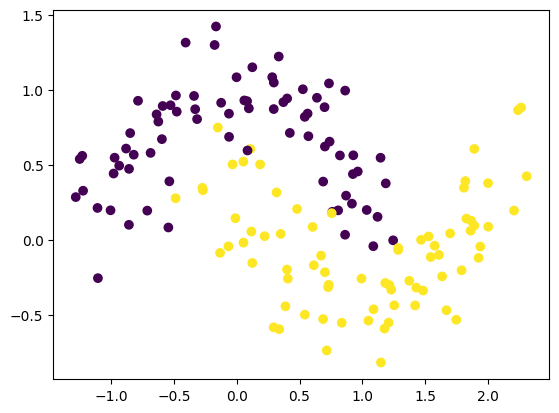

In [ ]:
plt.scatter(X_moons[:,0],X_moons[:,1],c=y_moons)

In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X_moons,y_moons,random_state=42,test_size=0.2)

In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt_clf=DecisionTreeClassifier(random_state=42)
dt_clf.fit(X_train,y_train)

DecisionTreeClassifier(random_state=42)

In [ ]:
dt_clf.score(X_train,y_train) ,dt_clf.score(X_test,y_test)

(1.0, 0.9)

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'criterion': ['entropy', 'gini'],
    'max_depth': [91, 92, 93, 94, 95],
    'min_samples_leaf': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
}

gsc_dt_clf = GridSearchCV(DecisionTreeClassifier(), param_grid, cv=3, verbose=0)
gsc_dt_clf.fit(X_train, y_train)

GridSearchCV(cv=3, estimator=DecisionTreeClassifier(),
             param_grid={'criterion': ['entropy', 'gini'],
                         'max_depth': [91, 92, 93, 94, 95],
                         'min_samples_leaf': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]})

In [ ]:
gsc_dt_clf.best_params_

{'criterion': 'entropy', 'max_depth': 91, 'min_samples_leaf': 2}

In [ ]:
gsc_dt_clf.best_estimator_.fit(X_train,y_train)

DecisionTreeClassifier(criterion='entropy', max_depth=91, min_samples_leaf=2)

In [ ]:
gsc_dt_clf.best_estimator_.score(X_train,y_train) ,gsc_dt_clf.best_estimator_.score(X_test,y_test)

(0.9666666666666667, 0.8666666666666667)

Iris Data

In [ ]:
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier

iris=load_iris(as_frame=True)
X_iris=iris.data[["petal length (cm)","petal width (cm)"]].values
y_iris=iris.target

tree_clf=DecisionTreeClassifier(max_depth=2,random_state=42)
tree_clf.fit(X_iris,y_iris)

DecisionTreeClassifier(max_depth=2, random_state=42)

In [ ]:
from pathlib import Path

IMAGES_PATH =Path() / "images" / "decision_trees"
IMAGES_PATH.mkdir(parents=True,exist_ok=True)

In [ ]:
from sklearn.tree import export_graphviz

export_graphviz(
    tree_clf,
    out_file=str(IMAGES_PATH / "iris_tree.dot"),
    feature_names=["petal length (cm)", "petal width (cm)"],
    class_names=iris.target_names,
    rounded=True,
    filled=True
)

In [ ]:
iris.target_names


array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

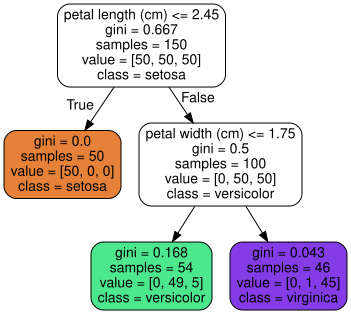

In [ ]:
from graphviz import Source
Source.from_file(IMAGES_PATH / "iris_tree.dot")

Estimating Class Probablities

In [ ]:
tree_clf.predict_proba([[5,1.5]]).round(3)

array([[0.   , 0.907, 0.093]])

In [ ]:
tree_clf.predict([[5,1.5]])


array([1])

Regularization Hyperparameters

In [ ]:
from sklearn.datasets import make_moons

In [ ]:
X_moons,y_moons =make_moons(n_samples=150,noise=0.2,random_state=42)

tree_clf1=DecisionTreeClassifier(random_state=42)
tree_clf2=DecisionTreeClassifier(min_samples_leaf=5,random_state=42)
tree_clf1.fit(X_moons,y_moons)
tree_clf2.fit(X_moons,y_moons)

DecisionTreeClassifier(min_samples_leaf=5, random_state=42)

In [ ]:
X_moons_test,y_moons_test=make_moons(n_samples=150,noise=0.2,random_state=53)

In [ ]:
tree_clf1.score(X_moons_test,y_moons_test) ,tree_clf2.score(X_moons_test,y_moons_test)

(0.8666666666666667, 0.92)

Regression

In [ ]:
from sklearn.tree import DecisionTreeRegressor

np.random.seed(42)
X_quad=np.random.rand(200,1)-0.5  # a single random input feature
y_quad=X_quad ** 2+0.025 * np.random.randn(200,1)

tree_reg=DecisionTreeRegressor(max_depth=2,random_state=42)
tree_reg.fit(X_quad,y_quad)

tree_reg=DecisionTreeRegressor(max_depth=2,random_state=42)
tree_reg.fit(X_quad,y_quad)

DecisionTreeRegressor(max_depth=2, random_state=42)

In [ ]:
tree_reg.score(X_quad,y_quad)

0.7966018355059642

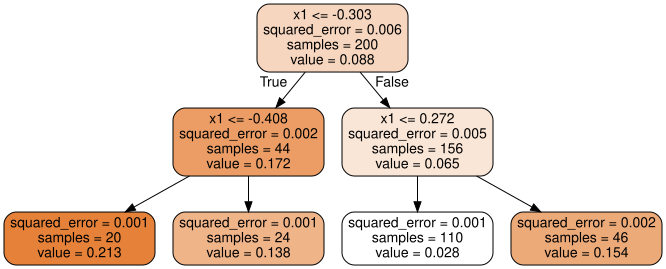

In [ ]:
export_graphviz(
    tree_reg,
    out_file=str(IMAGES_PATH / "regression_tree.dot"),
    feature_names=["x1"],
    rounded=True,
    filled=True
)
Source.from_file(IMAGES_PATH / "regression_tree.dot")
